<a href="https://colab.research.google.com/github/Ganitha-N/MLA0203-Fundamentals-of-Machine-Learning/blob/main/Lab(FOML).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
data = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Weak', 'Cool', 'Change', 'No'],
    ['Sunny', 'Warm', 'High', 'Weak', 'Warm', 'Same', 'Yes']
]

h = data[0][:-1]

for row in data:
    if row[-1] == 'Yes':
        for i in range(len(h)):
            if h[i] != row[i]:
                h[i] = '?'

print("Final Hypothesis:", h)

Final Hypothesis: ['Sunny', 'Warm', '?', '?', 'Warm', 'Same']


In [5]:
import numpy as np

data = np.array([
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Weak', 'Cool', 'Change', 'No'],
    ['Sunny', 'Warm', 'High', 'Weak', 'Warm', 'Same', 'Yes']
])

X, y = data[:, :-1], data[:, -1]

# Initialize Specific and General Boundaries
S = X[0].copy()
G = [['?' for _ in range(len(S))]]

for x, label in zip(X, y):
    if label == 'Yes':
        # Update Specific Boundary
        for i in range(len(S)):
            if x[i] != S[i]:
                S[i] = '?'
        # Remove inconsistent hypotheses from G
        G = [g for g in G if all(g[i] == '?' or g[i] == x[i] for i in range(len(S)))]
    else:
        # Update General Boundary
        new_G = []
        for g in G:
            # If g is inconsistent with the negative example
            if all(g[i] == '?' or g[i] == x[i] for i in range(len(S))):
                for i in range(len(S)):
                    if g[i] == '?' and S[i] != '?' and S[i] != x[i]:
                        g_new = g.copy()
                        g_new[i] = S[i]
                        if g_new not in new_G:
                            new_G.append(g_new)
            else:
                new_G.append(g)
        # Remove hypotheses from G that are not more general than S
        G = [g for g in new_G if all(g[i] == '?' or g[i] == S[i] for i in range(len(S)))]

print("Specific Boundary S:", S)
print("General Boundary G:", G)

Specific Boundary S: ['Sunny' 'Warm' '?' '?' 'Warm' 'Same']
General Boundary G: [[np.str_('Sunny'), '?', '?', '?', '?', '?'], ['?', np.str_('Warm'), '?', '?', '?', '?'], ['?', '?', '?', '?', np.str_('Warm'), '?'], ['?', '?', '?', '?', '?', np.str_('Same')]]


Prediction: setosa


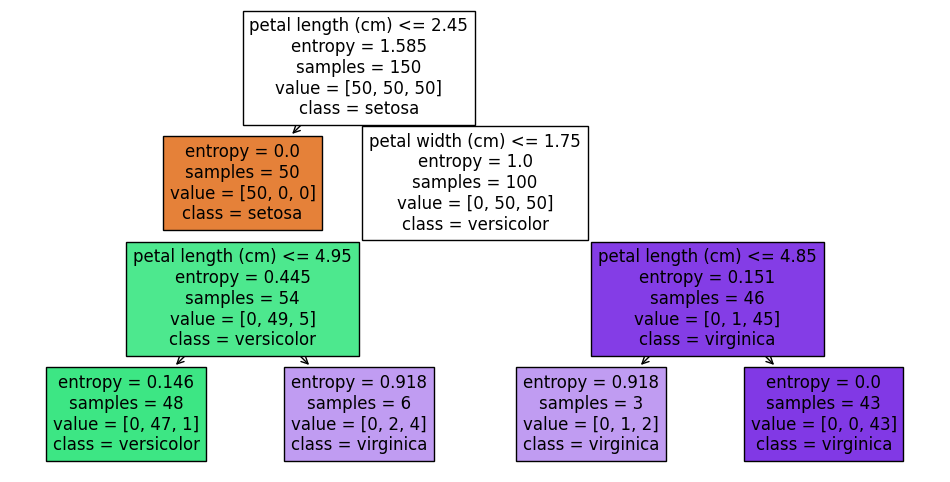

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

iris = load_iris()
X, y = iris.data, iris.target

model = DecisionTreeClassifier(criterion='entropy', max_depth=3)
model.fit(X, y)

print("Prediction:", iris.target_names[model.predict([[5.1,3.5,1.4,0.2]])[0]])

plt.figure(figsize=(12,6))
plot_tree(model, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.96


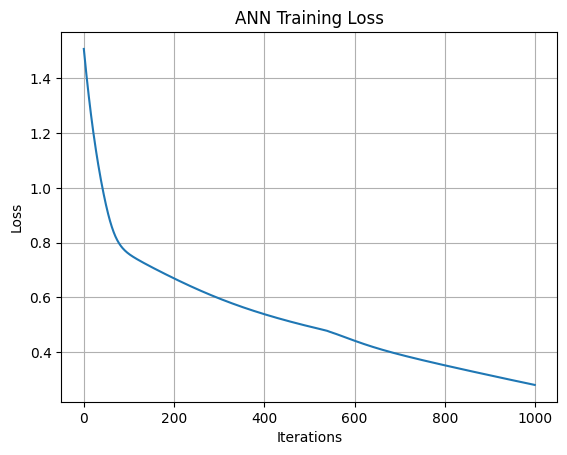

In [9]:
from sklearn.datasets import load_iris
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data, iris.target

model = MLPClassifier(hidden_layer_sizes=(10,), max_iter=1000,
                      random_state=1)
model.fit(X, y)

print("Accuracy:", model.score(X, y))

plt.plot(model.loss_curve_)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("ANN Training Loss")
plt.grid()
plt.show()

Accuracy: 1.0


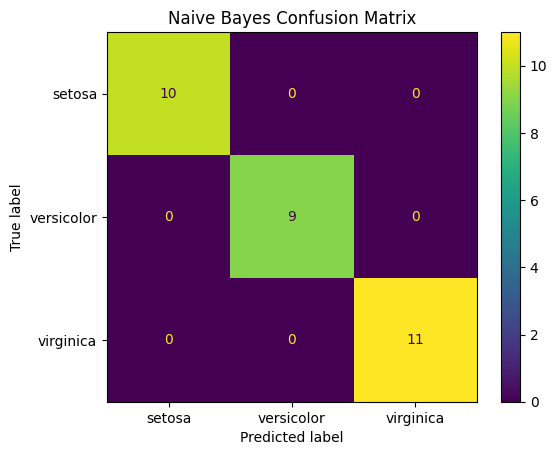

In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = GaussianNB()
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))

cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot()
plt.title("Naive Bayes Confusion Matrix")
plt.show()

Accuracy: 0.9


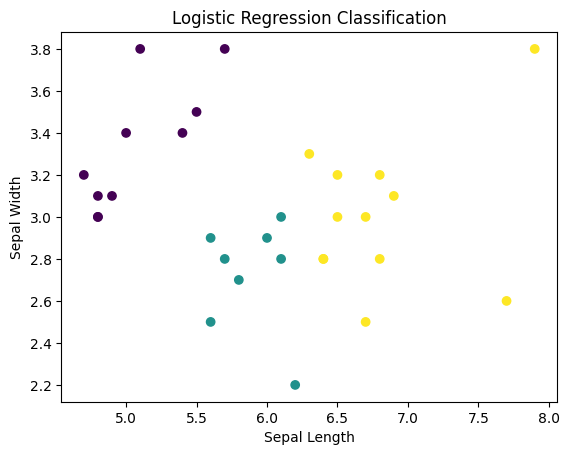

In [13]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data[:, :2], iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))

plt.scatter(X_test[:,0], X_test[:,1], c=pred)
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Logistic Regression Classification")
plt.show()

Predicted: 5.8
Slope: 0.6


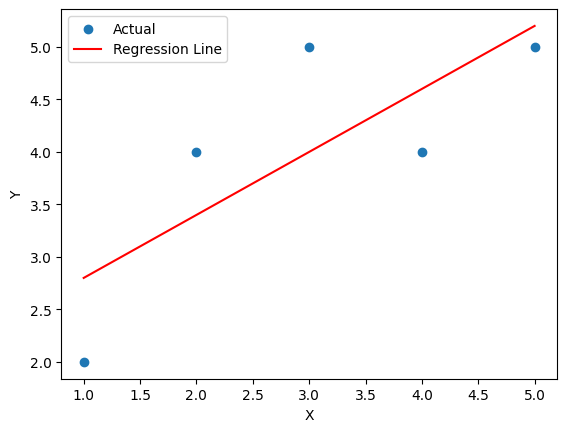

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

X = np.array([[1],[2],[3],[4],[5]])
y = np.array([2,4,5,4,5])

model = LinearRegression()
model.fit(X, y)

pred = model.predict(X)

print("Predicted:", model.predict([[6]])[0])
print("Slope:", model.coef_[0])

plt.scatter(X, y, label="Actual")
plt.plot(X, pred, color='red', label="Regression Line")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

Linear Prediction: 99.0
Polynomial Prediction: 121.00000000000003


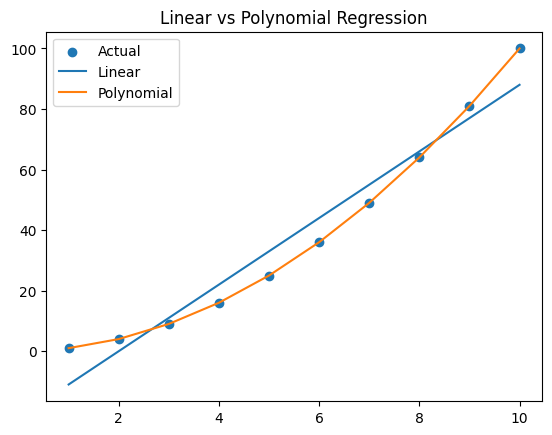

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

X = np.arange(1,11).reshape(-1,1)
y = np.array([1,4,9,16,25,36,49,64,81,100])

linear = LinearRegression().fit(X, y)

poly = PolynomialFeatures(degree=2)
Xp = poly.fit_transform(X)
model = LinearRegression().fit(Xp, y)

print("Linear Prediction:", linear.predict([[11]])[0])
print("Polynomial Prediction:", model.predict(poly.transform([[11]]))[0])

plt.scatter(X, y, label="Actual")
plt.plot(X, linear.predict(X), label="Linear")
plt.plot(X, model.predict(Xp), label="Polynomial")
plt.legend()
plt.title("Linear vs Polynomial Regression")
plt.show()

Cluster Labels: [2 0 1 1 1 1 0 1 2 1]


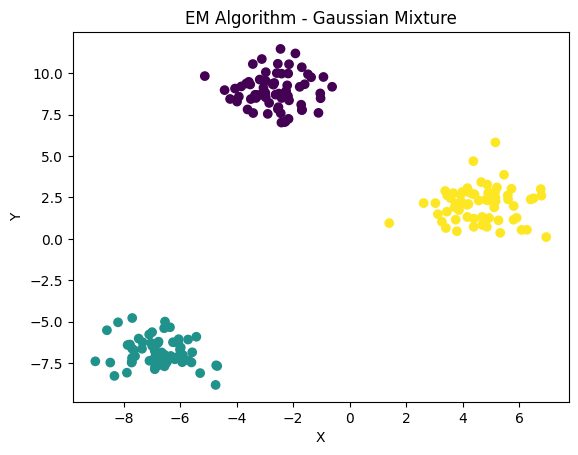

In [17]:
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

X, y = make_blobs(n_samples=200, centers=3,
                  random_state=42)

model = GaussianMixture(n_components=3, random_state=42)
model.fit(X)

labels = model.predict(X)

print("Cluster Labels:", labels[:10])

plt.scatter(X[:,0], X[:,1], c=labels)
plt.title("EM Algorithm - Gaussian Mixture")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

Credit Score Class: 1
Accuracy: 1.0


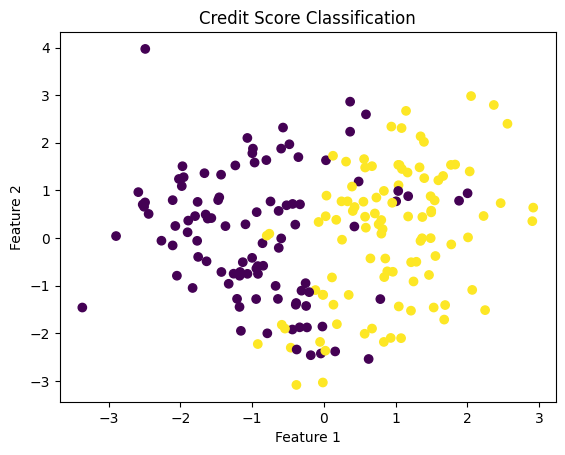

In [19]:
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=200, n_features=4,
                          random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X, y)

print("Credit Score Class:", model.predict([X[0]])[0])
print("Accuracy:", model.score(X, y))

plt.scatter(X[:,0], X[:,1], c=y)
plt.title("Credit Score Classification")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Flower: setosa
Accuracy: 0.8533333333333334


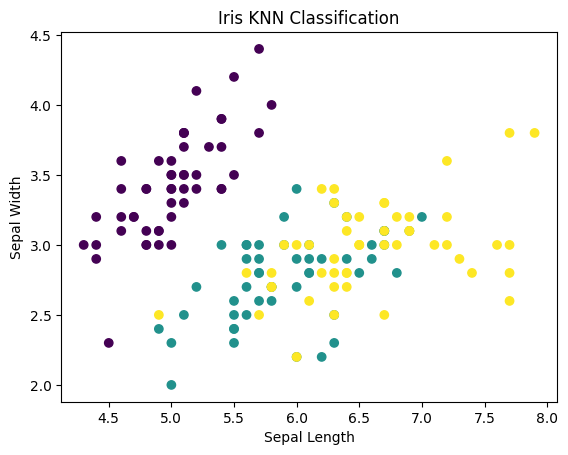

In [20]:
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data[:, :2], iris.target

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X, y)

print("Flower:", iris.target_names[model.predict([[5.1,3.5]])[0]])
print("Accuracy:", model.score(X, y))

plt.scatter(X[:,0], X[:,1], c=y)
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Iris KNN Classification")
plt.show()

Predicted Car Price: 12.500000000000002 Lakhs


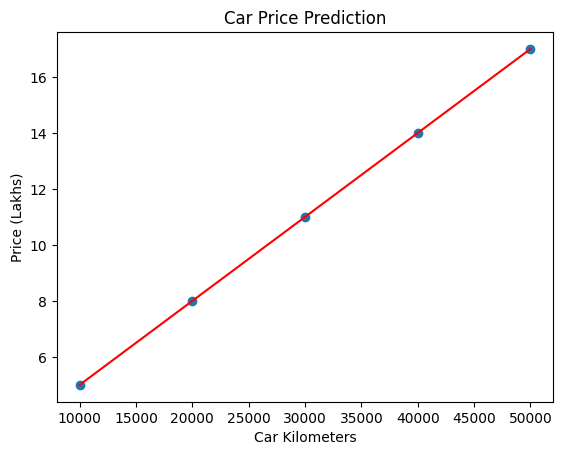

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

X = np.array([[10000],[20000],[30000],[40000],[50000]])
y = np.array([5,8,11,14,17])  # Price in lakhs

model = LinearRegression()
model.fit(X, y)

print("Predicted Car Price:", model.predict([[35000]])[0], "Lakhs")

plt.scatter(X, y)
plt.plot(X, model.predict(X), color='red')
plt.xlabel("Car Kilometers")
plt.ylabel("Price (Lakhs)")
plt.title("Car Price Prediction")
plt.show()

Predicted Price: 45.56896551724138 Lakhs


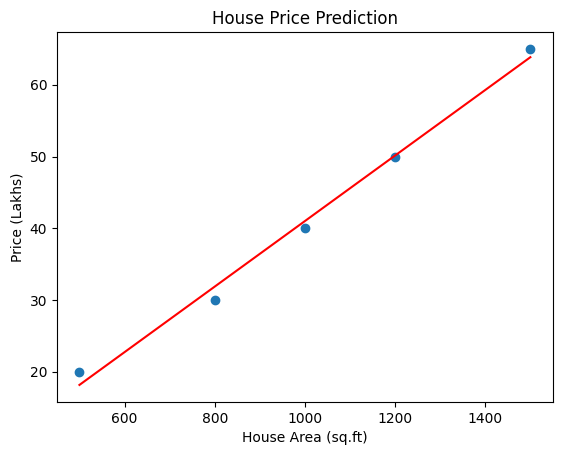

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

X = np.array([[500],[800],[1000],[1200],[1500]])
y = np.array([20,30,40,50,65])  # Lakhs

model = LinearRegression()
model.fit(X, y)

print("Predicted Price:", model.predict([[1100]])[0], "Lakhs")

plt.scatter(X, y)
plt.plot(X, model.predict(X), color='red')
plt.xlabel("House Area (sq.ft)")
plt.ylabel("Price (Lakhs)")
plt.title("House Price Prediction")
plt.show()

Prediction: setosa
Accuracy: 0.96


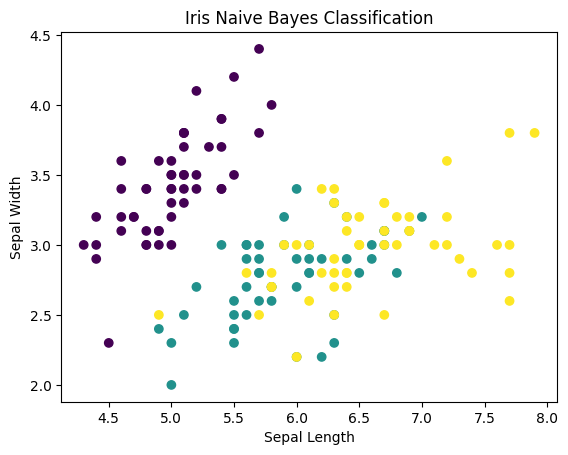

In [24]:
from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data, iris.target

model = GaussianNB()
model.fit(X, y)

print("Prediction:", iris.target_names[model.predict([[5.1,3.5,1.4,0.2]])[0]])
print("Accuracy:", model.score(X, y))

plt.scatter(X[:,0], X[:,1], c=y)
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Iris Naive Bayes Classification")
plt.show()

KNN Accuracy: 1.0
Decision Tree Accuracy: 1.0
Naive Bayes Accuracy: 1.0
Logistic Regression Accuracy: 1.0


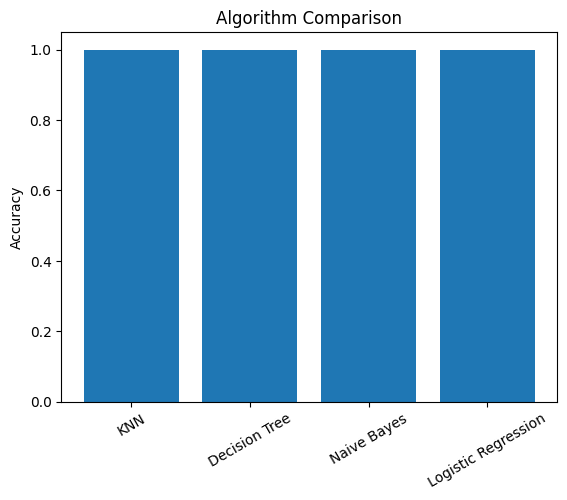

In [26]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

models = {
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000)
}

scores = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    scores.append(acc)
    print(name, "Accuracy:", acc)

plt.bar(models.keys(), scores)
plt.ylabel("Accuracy")
plt.title("Algorithm Comparison")
plt.xticks(rotation=30)
plt.show()

Mobile Price Range: 2
Accuracy: 1.0


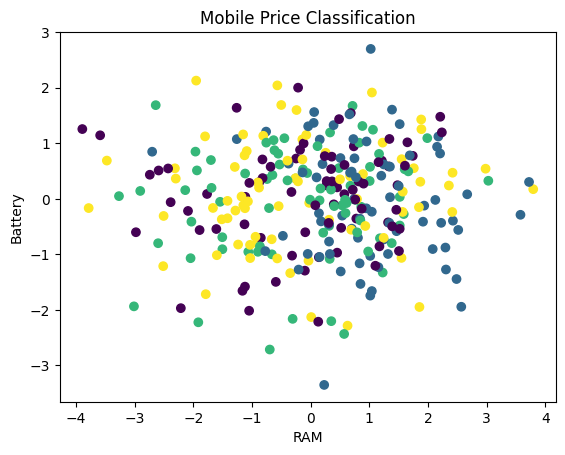

In [28]:
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=300, n_features=5,
                           n_classes=4, n_informative=4,
                           n_redundant=0, random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X, y)

print("Mobile Price Range:", model.predict([X[0]])[0])
print("Accuracy:", model.score(X, y))

plt.scatter(X[:,0], X[:,1], c=y)
plt.xlabel("RAM")
plt.ylabel("Battery")
plt.title("Mobile Price Classification")
plt.show()

Prediction: versicolor
Accuracy: 0.71


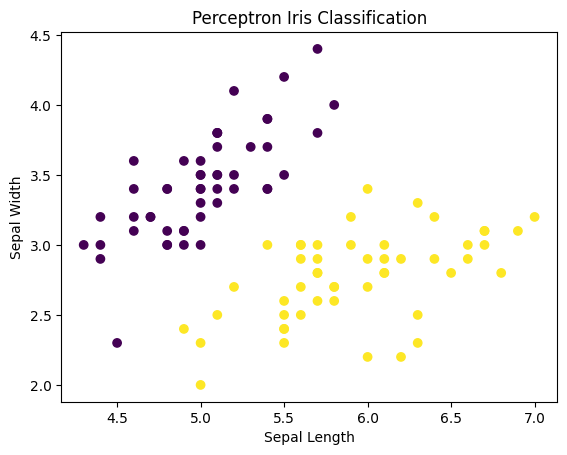

In [30]:
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data[:100, :2], iris.target[:100]

model = Perceptron(max_iter=1000, random_state=42)
model.fit(X, y)

print("Prediction:", iris.target_names[model.predict([[5.1,3.5]])[0]])
print("Accuracy:", model.score(X, y))

plt.scatter(X[:,0], X[:,1], c=y)
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Perceptron Iris Classification")
plt.show()

Loan Status: 0
Accuracy: 1.0


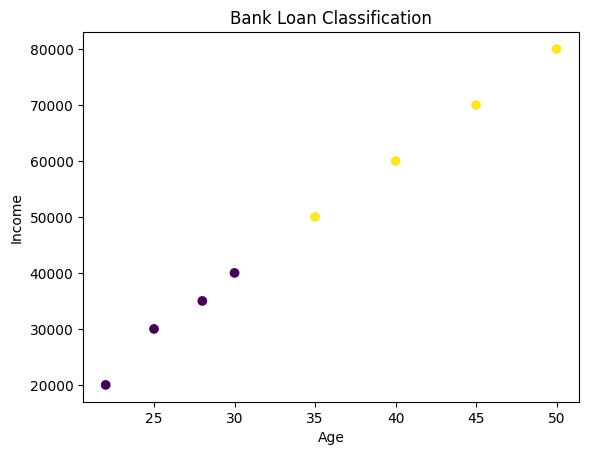

In [32]:
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt

X = [[25,30000],[35,50000],[45,70000],[22,20000],
     [40,60000],[30,40000],[50,80000],[28,35000]]
y = [0,1,1,0,1,0,1,0]  # 0=Reject, 1=Approve

model = GaussianNB()
model.fit(X, y)

print("Loan Status:", model.predict([[32,45000]])[0])
print("Accuracy:", model.score(X, y))

plt.scatter([a[0] for a in X], [a[1] for a in X], c=y)
plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Bank Loan Classification")
plt.show()

Next Month Sales: 306.060606060606


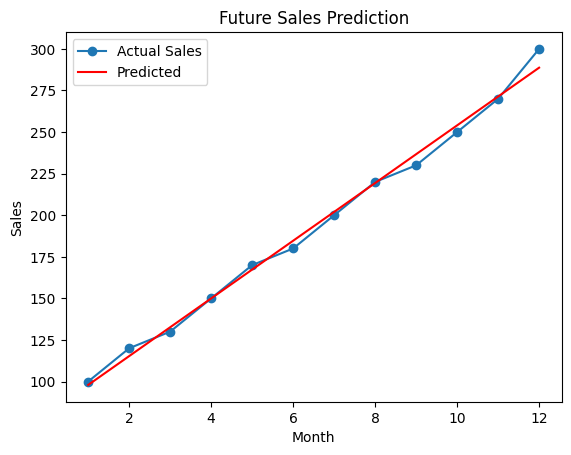

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

X = np.arange(1,13).reshape(-1,1)
y = np.array([100,120,130,150,170,180,
              200,220,230,250,270,300])

model = LinearRegression()
model.fit(X, y)

print("Next Month Sales:", model.predict([[13]])[0])

plt.plot(X, y, marker='o', label="Actual Sales")
plt.plot(X, model.predict(X), color='red', label="Predicted")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Future Sales Prediction")
plt.legend()
plt.show()